In [2]:
import gensim.downloader as api

model = api.load('word2vec-google-news-300')

[==================================================] 100.0% 1662.8/1662.8MB downloaded


In [ ]:
from sklearn.decomposition import PCA #Principal Component Analysis
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

v_king = model['king']
v_man = model['man']
v_woman = model['woman']
v_queen = model['queen']
v_result = v_king - v_man + v_woman



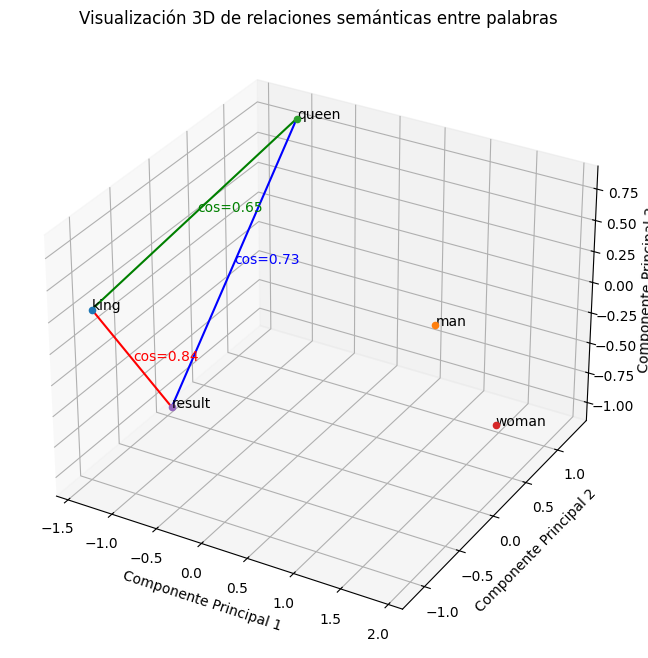

In [5]:
words_to_plot = ['king', 'man', 'queen','woman','result']
vectors_to_plot = [v_king, v_man, v_queen,v_woman,v_result]

pca = PCA(n_components=3)
reduced = pca.fit_transform(vectors_to_plot) # reducción de dimensionalidad
coords = {word: reduced[i] for i, word in enumerate(words_to_plot)} # diccionario de llave valor, donde es palabra - valor

def cos(a,b):
    return cosine_similarity([a],[b])[0][0]

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111, projection='3d') #Agregar ejes 3D

for word, vec in coords.items():
    ax.scatter(vec[0], vec[1], vec[2])
    ax.text(vec[0], vec[1], vec[2], word)
    
result = coords['result']
king = coords['king']
queen = coords['queen']
#Triangulo rojo para ver que tan cerca está uno del otro

#Result <-> King
ax.plot([result[0], king[0]], [result[1], king[1]], [result[2], king[2]], color='r')
mid_rk = (result + king) / 2.0
ax.text(mid_rk[0], mid_rk[1], mid_rk[2], f"cos={cos(v_result,v_king):.2f}", color='r')

#King <-> Queen
ax.plot([king[0], queen[0]], [king[1], queen[1]], [king[2], queen[2]], color='g')
mid_rk = (queen + king) / 2.0
ax.text(mid_rk[0], mid_rk[1], mid_rk[2], f"cos={cos(v_king,v_queen):.2f}", color='g')

#Result <-> Queen
ax.plot([result[0], queen[0]], [result[1], queen[1]], [result[2], queen[2]], color='b')
mid_rk = (queen + result) / 2.0
ax.text(mid_rk[0], mid_rk[1], mid_rk[2], f"cos={cos(v_result,v_queen):.2f}", color='b')

ax.set_title("Visualización 3D de relaciones semánticas entre palabras")
ax.set_xlabel("Componente Principal 1")
ax.set_ylabel("Componente Principal 2")
ax.set_zlabel("Componente Principal 3")
# Calcular y mostrar similitudes coseno
plt.show()


In [ ]:
similar_words = model.most_similar(positive=[v_result], topn=10)
print("Palabras más similares a la operación 'king - man + woman':")
for word, similarity in similar_words:
    print(f"{word}: {similarity:.4f}")

Palabras más similares a 'result':
king: 0.8449
queen: 0.7301
monarch: 0.6455
princess: 0.6156
crown_prince: 0.5819
prince: 0.5777
kings: 0.5614
sultan: 0.5377
Queen_Consort: 0.5344
queens: 0.5290


In [7]:
similar_words = model.most_similar(positive=[v_queen], topn=10)
print("Palabras más similares a la operación v_queen:")
for word, similarity in similar_words:
    print(f"{word}: {similarity:.4f}")

Palabras más similares a la operación v_queen:
queen: 1.0000
queens: 0.7399
princess: 0.7071
king: 0.6511
monarch: 0.6384
very_pampered_McElhatton: 0.6357
Queen: 0.6163
NYC_anglophiles_aflutter: 0.6061
Queen_Consort: 0.5924
princesses: 0.5908


In [8]:
similar_words = model.most_similar(positive=[v_king], topn=10)
print("Palabras más similares a la operación v_king:")
for word, similarity in similar_words:
    print(f"{word}: {similarity:.4f}")

Palabras más similares a la operación v_king:
king: 1.0000
kings: 0.7138
queen: 0.6511
monarch: 0.6413
crown_prince: 0.6204
prince: 0.6160
sultan: 0.5865
ruler: 0.5798
princes: 0.5647
Prince_Paras: 0.5433
